# Bank Account Fraud: exploratory analysis

What the BAF `Base.csv` data looks like, and which project decisions it supports. Every
section ends with a **Decision** paragraph naming the decision or ADR it backs.

The data is loaded through the project's own dataset-side Application module, so the
-1 sentinels and negative `intended_balcon_amount` are already missing values here,
exactly as the model sees them.

**Months 0–5 only**, except in section 5 (drift): the Test Months (6–7) are kept out of
every analysis that could shape a modelling choice. Only aggregates are shown, never
individual rows. A **fraud rate** here is the share of Applications that are Fraudulent
Applications.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud_api.application import CATEGORIES, FIELDS, SENTINEL_FIELDS, from_dataset
from fraud_api.evaluation import AGE_GROUP_BOUNDARY
from fraud_api.training import TEST_MONTHS, TRAINING_MONTHS, VALIDATION_MONTH

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw = pd.read_csv(ROOT / "data" / "Base.csv")  # read once; section 3 needs the raw values
dataset = from_dataset(raw)
everything = dataset.applications.assign(fraud=dataset.labels, month=dataset.months)
months_0_5 = everything[everything["month"] <= VALIDATION_MONTH]

# One look for every chart: the project's palette, recessive axes, no chart junk.
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c9c8c2"
INK, INK_2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "axes.titlecolor": INK,
        "axes.labelcolor": INK_2,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "axes.edgecolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "legend.frameon": False,
    }
)


def percent_axis(ax, axis="y"):
    formatter = plt.FuncFormatter(lambda v, _: f"{v:.1%}" if v < 0.1 else f"{v:.0%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def fraud_rate(frame, by):
    return frame.groupby(by, observed=True)["fraud"].agg(rate="mean", applications="size")


def table(frame, **formats):
    # A copy with each named column formatted, so saved outputs are plain, stable text.
    shown = frame.copy()
    for column, spec in formats.items():
        shown[column] = shown[column].map(spec.format)
    return shown


def no_y_grid(ax):
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)


print(f"{len(months_0_5):,} Applications in Months 0–5, {len(FIELDS)} fields")

794,989 Applications in Months 0–5, 29 fields


## 1. Overview and fraud rate by Month

Fraudulent Applications: 8,151 of 794,989 (1.03%)


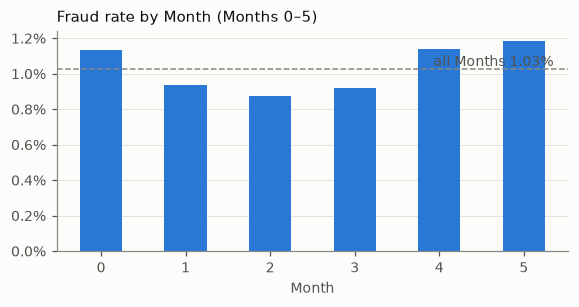

,rate,applications
month,,
0,1.13%,"132,440"
1,0.94%,"127,620"
2,0.87%,"136,979"
3,0.92%,"150,936"
4,1.14%,"127,691"
5,1.18%,"119,323"


In [2]:
overall = months_0_5["fraud"].mean()
by_month = fraud_rate(months_0_5, "month")
fraudulent = months_0_5["fraud"].sum()
print(f"Fraudulent Applications: {fraudulent:,} of {len(months_0_5):,} ({overall:.2%})")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(by_month.index, by_month["rate"], width=0.5, color=BLUE)
ax.axhline(overall, color=MUTED, linewidth=1, linestyle="--")
ax.text(5.35, overall, f"all Months {overall:.2%}", va="bottom", ha="right", color=INK_2)
ax.set_title("Fraud rate by Month (Months 0–5)")
ax.set_xlabel("Month")
percent_axis(ax)
plt.show()
table(by_month, rate="{:.2%}", applications="{:,}")

**Decision.** About one Application in a hundred is fraudulent, and the rate moves from
Month to Month. Accuracy would be 99% for a model that flags nothing, so the project
measures **Recall@5%FPR** (the share of Fraudulent Applications flagged when at most 5% of
Legitimate Applications are flagged) and PR-AUC. Because the rate shifts over time, the data is split by
Month, never at random: train on Months 0–4, choose the Threshold on Month 5, test on
Months 6–7 (**ADR 0001**).

## 2. Missing values and their fraud signal

The dataset writes -1 for a missing value in five fields; negative
`intended_balcon_amount` is treated the same way (section 3).

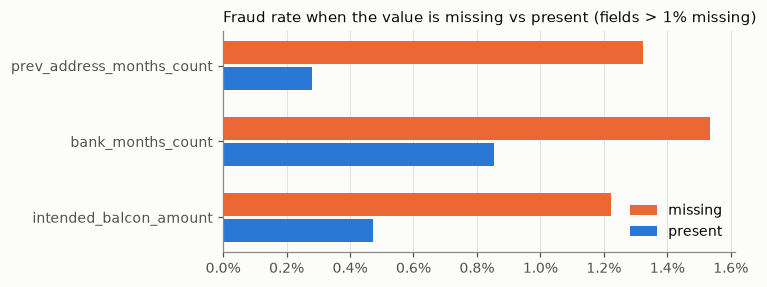

,share missing,fraud rate when missing,fraud rate when present
field,,,
prev_address_months_count,71.50%,1.32%,0.28%
current_address_months_count,0.38%,0.30%,1.03%
bank_months_count,25.10%,1.54%,0.85%
session_length_in_minutes,0.19%,0.86%,1.03%
device_distinct_emails_8w,0.04%,0.97%,1.03%
intended_balcon_amount,73.70%,1.22%,0.47%


In [3]:
rows = []
for field in [*SENTINEL_FIELDS, "intended_balcon_amount"]:
    missing = months_0_5[field].isna()
    rows.append(
        {
            "field": field,
            "share missing": missing.mean(),
            "fraud rate when missing": months_0_5.loc[missing, "fraud"].mean(),
            "fraud rate when present": months_0_5.loc[~missing, "fraud"].mean(),
        }
    )
missingness = pd.DataFrame(rows).set_index("field")

shown = missingness[missingness["share missing"] > 0.01]
fig, ax = plt.subplots(figsize=(6, 2.6))
y = np.arange(len(shown))
ax.barh(y - 0.17, shown["fraud rate when missing"], height=0.3, color=ORANGE, label="missing")
ax.barh(y + 0.17, shown["fraud rate when present"], height=0.3, color=BLUE, label="present")
ax.set_yticks(y, shown.index)
ax.invert_yaxis()
no_y_grid(ax)
percent_axis(ax, "x")
ax.set_title("Fraud rate when the value is missing vs present (fields > 1% missing)")
ax.legend(loc="lower right")
plt.show()
table(missingness, **dict.fromkeys(missingness.columns, "{:.2%}"))

**Decision.** Missingness is informative: Applicants without a previous address are
fraudulent several times as often as those with one, and a missing bank-months count
nearly doubles the rate. So missing values are **kept as missing**, never imputed away
for LightGBM, which learns its own direction for them; the logistic-regression baseline
gets explicit **missing-value indicators** next to its median imputation. The API
accepts `null` in exactly these six fields.

## 3. Privacy artefacts

The BAF authors protected Applicants' privacy by coarsening some fields and adding noise
to others. This section reads the raw file directly, since the Application module has
already converted the negative amounts.

income values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
customer_age values: [10, 20, 30, 40, 50, 60, 70, 80, 90]
proposed_credit_limit values: [190, 200, 210, 490, 500, 510, 990, 1000, 1500, 1900, 2000, 2100]
negative intended_balcon_amount: 73.7% of Applications, median -1.01, minimum -15.53
share of negative values between -2.5 and 0 (charted): 99.77%


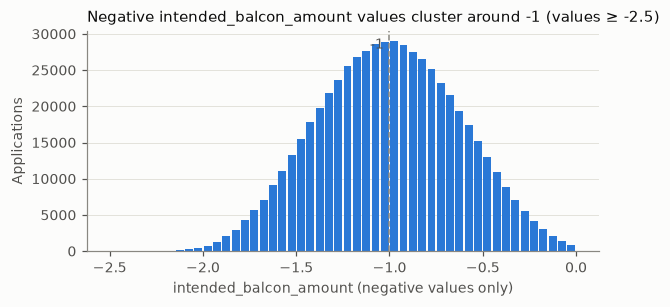

In [4]:
raw_0_5 = raw[raw["month"] <= VALIDATION_MONTH]
print("income values:", sorted(raw_0_5["income"].round(6).unique().tolist()))
print("customer_age values:", sorted(raw_0_5["customer_age"].unique().tolist()))
print(
    "proposed_credit_limit values:",
    sorted(raw_0_5["proposed_credit_limit"].astype(int).unique().tolist()),
)

negative = raw_0_5.loc[raw_0_5["intended_balcon_amount"] < 0, "intended_balcon_amount"]
print(
    f"negative intended_balcon_amount: {len(negative) / len(raw_0_5):.1%} of Applications, "
    f"median {negative.median():.2f}, minimum {negative.min():.2f}"
)
print(f"share of negative values between -2.5 and 0 (charted): {(negative >= -2.5).mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(negative, bins=np.arange(-2.5, 0.01, 0.05), color=BLUE, rwidth=0.85)
ax.axvline(-1, color=MUTED, linewidth=1, linestyle="--")
ax.text(-1.03, ax.get_ylim()[1] * 0.92, "-1", ha="right", color=INK_2)
ax.set_title("Negative intended_balcon_amount values cluster around -1 (values ≥ -2.5)")
ax.set_xlabel("intended_balcon_amount (negative values only)")
ax.set_ylabel("Applications")
plt.show()

**Decision.** `income` takes nine values (deciles), `customer_age` nine decades, and
`proposed_credit_limit` twelve values, so the **API contract accepts only those values**
and rejects anything in between. The negative `intended_balcon_amount` values form one
bump centred on -1: the -1 "missing" sentinel smeared by the authors' noise, not real
negative balances. A thin tail reaches further down (the printed minimum and share above),
too small to be a population of its own. The Application module therefore turns **every
negative amount into a missing value**, matching the other sentinel fields.

## 4. Risk factors

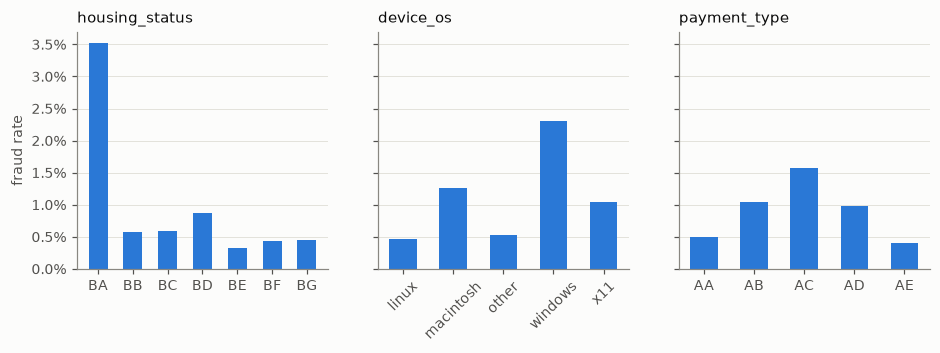

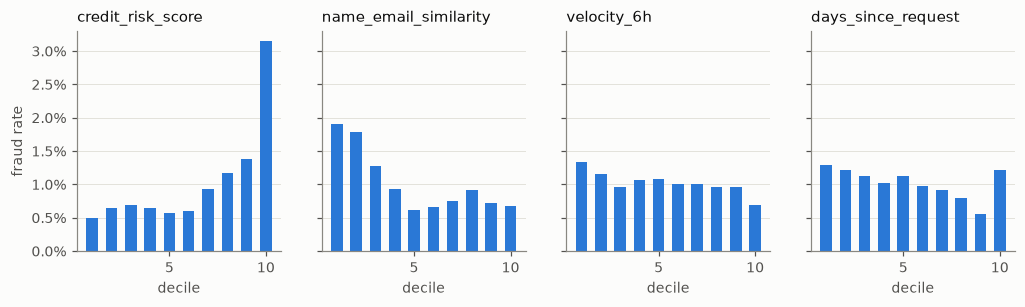

,credit_risk_score,name_email_similarity,velocity_6h,days_since_request
decile,,,,
1,0.50%,1.90%,1.34%,1.29%
2,0.65%,1.79%,1.16%,1.22%
3,0.70%,1.28%,0.96%,1.13%
4,0.65%,0.93%,1.07%,1.03%
5,0.57%,0.62%,1.08%,1.12%
6,0.61%,0.66%,1.00%,0.97%
7,0.93%,0.76%,1.01%,0.92%
8,1.17%,0.92%,0.96%,0.79%
9,1.38%,0.73%,0.97%,0.56%


rate applications
payment_type      AA         0.50%      208,920
                  AB         1.04%      288,182
                  AC         1.58%      198,579
                  AD         0.98%       99,060
                  AE         0.40%          248
employment_status CA         1.13%      571,543
                  CB         0.64%      115,450
                  CC         2.34%       31,247
                  CD         0.40%       22,005
                  CE         0.21%       18,143
                  CF         0.19%       36,229
                  CG         1.34%          372
housing_status    BA         3.52%      129,775
                  BB         0.58%      204,590
                  BC         0.59%      301,879
                  BD         0.87%       17,956
                  BE         0.32%      139,209
                  BF         0.44%        1,358
                  BG         0.45%          222
source            INTERNET   1.02%      789,252
                  TELEAPP    1.39%        5,737
device_os         linux      0.46%      267,680
                  macintosh  1.26%       43,011
                  other      0.53%      265,427
                  windows    2.30%      212,925
                  x11        1.04%        5,946

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, field in zip(axes, ["housing_status", "device_os", "payment_type"], strict=True):
    rates = fraud_rate(months_0_5, field)
    ax.bar(rates.index, rates["rate"], width=0.55, color=BLUE)
    ax.set_title(field)
    ax.tick_params(axis="x", labelrotation=45 if field == "device_os" else 0)
    percent_axis(ax)
axes[0].set_ylabel("fraud rate")
plt.show()

numeric = ["credit_risk_score", "name_email_similarity", "velocity_6h", "days_since_request"]
by_decile = pd.DataFrame(
    {
        field: months_0_5.groupby(pd.qcut(months_0_5[field], 10, labels=False, duplicates="drop"))[
            "fraud"
        ].mean()
        for field in numeric
    }
)
by_decile.index = by_decile.index + 1
by_decile.index.name = "decile"
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), sharey=True)
for ax, field in zip(axes, numeric, strict=True):
    rates = by_decile[field]
    ax.bar(rates.index, rates.values, width=0.6, color=BLUE)
    ax.set_title(field)
    ax.set_xlabel("decile")
    percent_axis(ax)
axes[0].set_ylabel("fraud rate")
plt.show()

display(table(by_decile, **dict.fromkeys(numeric, "{:.2%}")))
summary = pd.concat({field: fraud_rate(months_0_5, field) for field in CATEGORIES})
table(summary, rate="{:.2%}", applications="{:,}")

**Decision.** Some single fields separate risk strongly (housing status `BA`, Windows
devices, the top `credit_risk_score` decile), but most relationships are non-linear and
interact: `credit_risk_score` is flat for its lower half and climbs only at the top. A
single-field rule on `credit_risk_score` is kept as the floor every model must beat (the
**baseline rule**, #7), and a **gradient-boosted tree model (LightGBM)** is the served
model because it can capture thresholds and interactions that a linear model can't. The
measured margin over a well-preprocessed logistic regression turned out modest (README,
"What the numbers say"). The
fixed category lists come from these tables.

## 5. Drift across Months

The only section that looks at the Test Months (6–7).

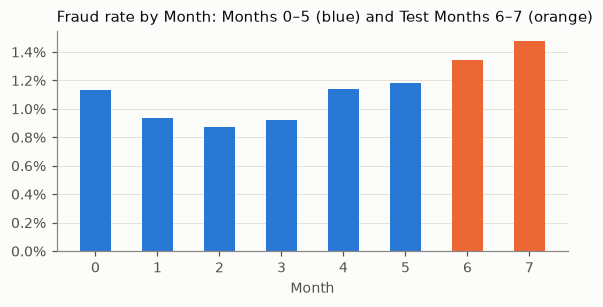

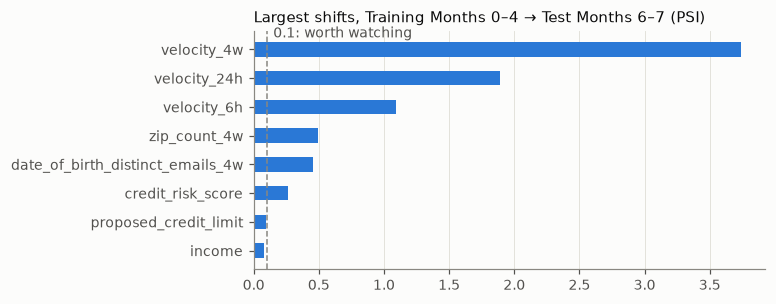

,rate,applications
month,,
0,1.13%,"132,440"
1,0.94%,"127,620"
2,0.87%,"136,979"
3,0.92%,"150,936"
4,1.14%,"127,691"
5,1.18%,"119,323"
6,1.34%,"108,168"
7,1.47%,"96,843"


,PSI
velocity_4w,3.739
velocity_24h,1.892
velocity_6h,1.089
zip_count_4w,0.491
date_of_birth_distinct_emails_4w,0.455
credit_risk_score,0.261
proposed_credit_limit,0.093
income,0.082
session_length_in_minutes,0.063
name_email_similarity,0.044


In [6]:
by_month = fraud_rate(everything, "month")
fig, ax = plt.subplots(figsize=(6, 2.6))
colors = [ORANGE if month in TEST_MONTHS else BLUE for month in by_month.index]
ax.bar(by_month.index, by_month["rate"], width=0.5, color=colors)
ax.set_title("Fraud rate by Month: Months 0–5 (blue) and Test Months 6–7 (orange)")
ax.set_xlabel("Month")
percent_axis(ax)
plt.show()


def bins(values, edges):
    # Deciles for continuous values, the values themselves for discrete ones;
    # a missing value is a bin of its own either way.
    if edges is None:
        return values.astype("object").where(values.notna(), "missing")
    binned = pd.cut(values.clip(edges[0], edges[-1]), edges, include_lowest=True)
    return binned.astype("object").where(values.notna(), "missing")


def psi(expected, actual):
    # Population stability index of actual against expected.
    discrete = expected.dtype == "category" or expected.nunique() <= 12
    edges = None if discrete else np.unique(np.quantile(expected.dropna(), np.linspace(0, 1, 11)))
    e = bins(expected, edges).value_counts(normalize=True)
    a = bins(actual, edges).value_counts(normalize=True)
    e, a = e.align(a, fill_value=0)
    e, a = e.clip(lower=1e-6), a.clip(lower=1e-6)
    return float(((a - e) * np.log(a / e)).sum())


training = everything[everything["month"].isin(TRAINING_MONTHS)]
test = everything[everything["month"].isin(TEST_MONTHS)]
drift = pd.Series({field: psi(training[field], test[field]) for field in FIELDS})
drift = drift.sort_values(ascending=False)
top = drift.head(8)[::-1]

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(top.index, top.values, height=0.5, color=BLUE)
ax.axvline(0.1, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.15, len(top) - 0.45, "0.1: worth watching", color=INK_2, va="center")
no_y_grid(ax)
ax.set_title("Largest shifts, Training Months 0–4 → Test Months 6–7 (PSI)")
plt.show()
display(table(by_month, rate="{:.2%}", applications="{:,}"))
table(drift.to_frame("PSI"), PSI="{:.3f}")

**Decision.** The fraud rate rises in the Test Months, and several features shift in
distribution, most of all the application-velocity counts (`velocity_4w`, `velocity_24h`,
`velocity_6h`), which move far past the usual 0.1 warning level; `zip_count_4w`,
`date_of_birth_distinct_emails_4w` and `credit_risk_score` (the baseline rule's only
input) are past it too. Missing-value shares and
the category mixes barely move (every field is measured, with missing as its own bin). A
random split would hide this drift; **splitting by Month (ADR 0001)** measures it. It also
explains why the Threshold chosen on Month 5 flags more than 5% of Legitimate
Applications in Months 6–7: the Model Version metadata reports that actual FPR next to
Recall@5%FPR rather than re-fitting the Threshold on the Test Months.

## 6. Age and fairness

fraud rate aged 50 or over: 2.21%, under 50: 0.75%


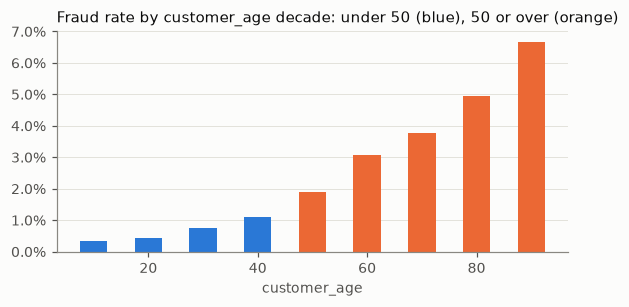

,rate,applications
customer_age,,
10,0.33%,"15,891"
20,0.45%,"199,514"
30,0.76%,"248,111"
40,1.12%,"182,239"
50,1.90%,"114,677"
60,3.08%,"28,306"
70,3.77%,"5,178"
80,4.94%,"1,013"
90,6.67%,60


In [7]:
by_age = fraud_rate(months_0_5, "customer_age")
older = months_0_5["customer_age"] >= AGE_GROUP_BOUNDARY
print(
    f"fraud rate aged 50 or over: {months_0_5.loc[older, 'fraud'].mean():.2%}, "
    f"under 50: {months_0_5.loc[~older, 'fraud'].mean():.2%}"
)

fig, ax = plt.subplots(figsize=(6, 2.6))
colors = [ORANGE if age >= AGE_GROUP_BOUNDARY else BLUE for age in by_age.index]
ax.bar(by_age.index, by_age["rate"], width=5, color=colors)
ax.set_title("Fraud rate by customer_age decade: under 50 (blue), 50 or over (orange)")
ax.set_xlabel("customer_age")
percent_axis(ax)
plt.show()
table(by_age, rate="{:.2%}", applications="{:,}")

**Decision.** Fraud rises steadily with age: Applicants aged 50 or over are about three
times as likely to submit a Fraudulent Application. A model that uses age, or anything
correlated with it, will flag older Applicants' Legitimate Applications more often. The
project keeps `customer_age` as a feature and **reports the FPR Ratio and the Precision Ratio
between the two Age Groups** next to every Recall@5%FPR, instead of hiding the disparity (**ADR 0003**).

## 7. Proxies for age

How much of age could a model recover from each other field? One measure for every
field: the correlation ratio, the square root of the share of age's variance explained by
the field's groups (its categories, or its deciles for continuous fields, with missing as
a group). 0 means the field says nothing about age, 1 that it determines it.

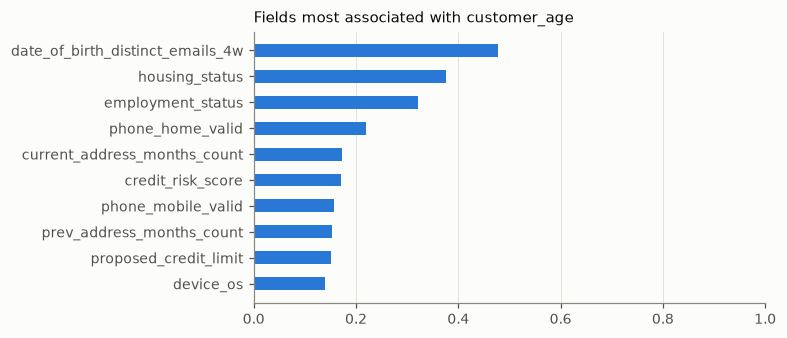

,association with age
date_of_birth_distinct_emails_4w,0.48
housing_status,0.38
employment_status,0.32
phone_home_valid,0.22
current_address_months_count,0.17
credit_risk_score,0.17
phone_mobile_valid,0.16
prev_address_months_count,0.15
proposed_credit_limit,0.15
device_os,0.14


In [8]:
def correlation_ratio(categories, values):
    groups = values.groupby(categories, observed=True)
    between = (groups.size() * (groups.mean() - values.mean()) ** 2).sum()
    return float(np.sqrt(between / ((values - values.mean()) ** 2).sum()))


age = months_0_5["customer_age"]
association = {}
for field in FIELDS:
    if field == "customer_age":
        continue
    values = months_0_5[field]
    discrete = values.dtype == "category" or values.nunique() <= 12
    edges = None if discrete else np.unique(np.quantile(values.dropna(), np.linspace(0, 1, 11)))
    association[field] = correlation_ratio(bins(values, edges).astype(str), age)
association = pd.Series(association).sort_values(ascending=False)
top = association.head(10)[::-1]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(top.index, top.values, height=0.5, color=BLUE)
no_y_grid(ax)
ax.set_xlim(0, 1)
ax.set_title("Fields most associated with customer_age")
plt.show()
table(association.to_frame("association with age"), **{"association with age": "{:.2f}"})

**Decision.** Several fields carry a real part of the age signal, so a model without
`customer_age` could still partly rebuild it from them. That is why **ADR 0003**
expected "fairness through unawareness" to leave much of the disparity in place while
costing recall. Measured later in the training pipeline (#30; README, "What the numbers
say"), on Model Version `lgbm-f5421b309a8c`: without age, the FPR Ratio on the Test Months
rose from 0.32 to 0.42, so most of the gap remained, while Recall@5%FPR moved by only
-0.3 points, so the expected recall cost barely showed. Without age the Precision Ratio
also fell, from 0.84 to 0.70: a Review would carry a less equal fraud risk across Age
Groups. That is the test the developer set on 10 November, so age stays a feature
(ADR 0003).